In [1]:
import agama, numpy
from astropy import units as u 
from astropy import constants as cnst
import h5py 
from matplotlib import pyplot as plt 

In [2]:
# open the output file and analyze it 
myfile=h5py.File("ferrers_bar.h5",'r')

In [13]:
myfile.keys()

<KeysViewHDF5 ['nbody_100', 'nbody_200', 'schwarzschild']>

In [14]:
type(myfile["schwarzschild"])

h5py._hl.group.Group

In [ ]:
def print_tree(group, indent=0):
    pad = "    " * indent
    for key, item in group.items():
        if isinstance(item, h5py.Group):          # public name; avoid h5py._hl.group.Group
            print(f"{pad}{key}/   ({len(item.attrs)} attrs)")
            print_tree(item, indent + 1)
        else:
            print(f"{pad}{key}   {item.shape} {item.dtype}")

with h5py.File("ferrers_bar.h5", "r") as f:
    print_tree(f)

nbody_100/   (28 attrs)
    initial_conditions   (100, 6) float64
    mass   (100,) float64
    potential_energy_external   (20001, 100) float32
    potential_energy_internal   (20001, 100) float32
    time   (20001,) float64
    trajectories   (20001, 100, 6) float32
nbody_200/   (28 attrs)
    initial_conditions   (200, 6) float64
    mass   (200,) float64
    potential_energy_external   (20001, 200) float32
    potential_energy_internal   (20001, 200) float32
    time   (20001,) float64
    trajectories   (20001, 200, 6) float32
schwarzschild/   (30 attrs)
    gridr   (11,) float64
    ics   (2000, 6) float64
    inputs/   (0 attrs)
        bar_ini   () object
        ext_ini   () object
    mass_model   (191,) float64
    mass_true   (191,) float64
    matrix_data_density   (2000, 191) float32
    orbit_times   (2000,) float64
    potential/   (1 attrs)
        bar/   (5 attrs)
        halo/   (3 attrs)
        thick_disk/   (4 attrs)
        thin_disk/   (4 attrs)
    sigma   (191

In [54]:
group = "nbody_100"
potential_energy_external = myfile[group]["potential_energy_external"][:]
potential_energy_internal = myfile[group]["potential_energy_internal"][:]
kinetic_energy = (1/2)*myfile[group]["mass"][:]*numpy.sum(myfile[group]["trajectories"][:,:,3:6]**2,axis=2)
timesteps = myfile[group]["time"][:]

In [55]:
E_total = potential_energy_external + potential_energy_internal + kinetic_energy
total_energy = numpy.sum(E_total,axis=1)
eDrift = numpy.abs((total_energy - total_energy[0]) / total_energy[0])

show the bar frame

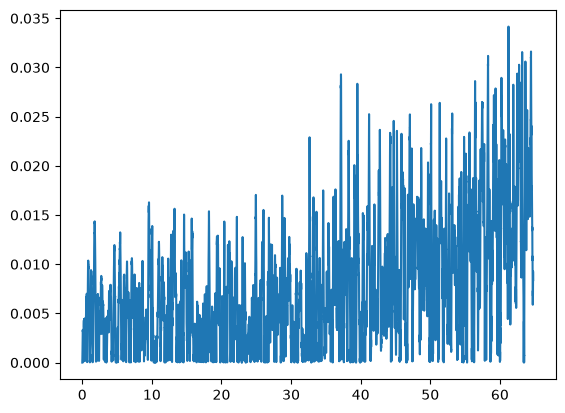

In [56]:
from matplotlib import pyplot as plt 
fig,axis=plt.subplots(1,1)
axis.plot(timesteps,eDrift)

In [57]:
trajectories = myfile[group]["trajectories"][:,:,:]